#Agrupamiento por K-means
-------

Carlos Francisco Montoya Urzua

Fecha: Lunes, 11 de mayo de 2026

Tomado de: https://www.geeksforgeeks.org/machine-learning/k-means-clustering-introduction/

K-Means Clustering agrupa puntos de datos similares en clústeres sin necesidad de datos etiquetados. Se utiliza para descubrir patrones ocultos cuando el objetivo es organizar los datos basándose en la similitud.

*Ayuda a identificar agrupaciones naturales en conjuntos de datos no etiquetados

*Funciona agrupando puntos según la distancia a los centros del grupo

*Comúnmente utilizado en segmentación de clientes, compresión de imágenes y descubrimiento de patrones

*Útil cuando necesitas estructura a partir de datos en bruto y desorganizados

##Funcionamiento del agrupamiento K-Means
Supongamos que se nos da un conjunto de datos de elementos con ciertas características y valores para estas características, como un vector. La tarea es categorizar esos elementos en grupos. Para lograr esto utilizaremos el algoritmo K-medias. "k" representa el número de grupos o grupos en los que queremos clasificar nuestros objetos.
  
El algoritmo categorizará los elementos en "k" grupos o grupos de similitud. Para calcular esa similitud usaremos la distancia euclidiana como medida. El algoritmo funciona de la siguiente manera:

*Inicialización: Comenzamos seleccionando aleatoriamente k centroides de clúster.

*Paso de asignación: Cada punto de datos se asigna al centroide más cercano, formando grupos.

*Paso de actualización: Tras la asignación, recalculamos el centroide de cada clúster promediando los puntos dentro de él.

*Repetir: Este proceso se repite hasta que los centroides ya no cambian o se alcanza el número máximo de iteraciones.

El objetivo es particionar el conjunto de datos en k conglomerados de modo que los puntos de datos dentro de cada clúster sean más similares entre sí que a los de otros clústeres.


Seleccionar el número correcto de clústeres es importante para una segmentación significativa; para ello usamos el método Elbow para el valor óptimo de k en KMeans, que es una herramienta gráfica utilizada para determinar el número óptimo de clústeres (k) en K-means.

##Usos del agrupamiento K-Means
K-Means es popular en una amplia variedad de aplicaciones debido a su simplicidad, eficiencia y eficacia. Aquí tienes por qué se usa ampliamente:

Segmentación de datos: Uno de los usos más comunes de K-Means es segmentar datos en grupos distintos. Por ejemplo, las empresas utilizan K-Means para agrupar a los clientes según comportamientos, como patrones de compra o interacción con la web.

Compresión de imágenes: K-Means puede usarse para reducir la complejidad de las imágenes agrupando píxeles similares en grupos, comprimiendo efectivamente la imagen. Esto es útil para el almacenamiento y procesamiento de imágenes.

Detección de anomalías: Los K-Means pueden aplicarse para detectar anomalías o valores atípicos identificando puntos de datos que no pertenecen a ninguno de los clústeres.

Agrupamiento de documentos: En el procesamiento de lenguaje natural (PLN), K-Means se utiliza para agrupar documentos o artículos similares. A menudo se utiliza en aplicaciones como sistemas de recomendaciones o categorización de noticias.

Organización de grandes conjuntos de datos: Al tratar con grandes conjuntos de datos, K-Means puede ayudar a organizar los datos en fragmentos más pequeños y manejables basados en similitudes, mejorando la eficiencia del análisis de datos.

##IMPLEMENTACION

Importar librerias necesarias

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

Generaremos un conjunto de datos sintético con make_blobs.

make_blobs(n_samples=500, n_features=2, centros=3): Genera 500 puntos de datos en un espacio 2D, agrupados en 3 clústeres.

plt.scatter(X[:, 0], X[:, 1]): Grafica el conjunto de datos en 2D, mostrando todos los puntos.

plt.show(): Muestra la trama

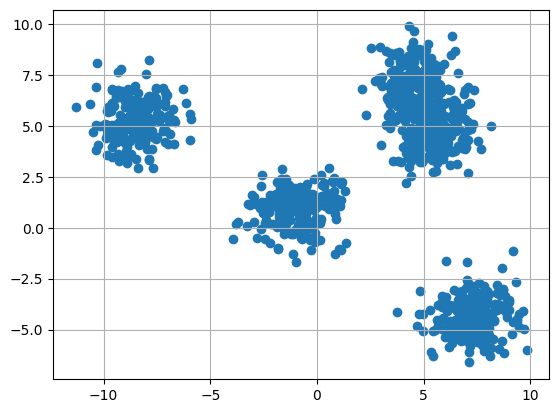

In [13]:
X,y = make_blobs(n_samples = 1000,n_features = 2,centers = 5,random_state = 29)

fig = plt.figure(0)
plt.grid(True)
plt.scatter(X[:,0],X[:,1])
plt.show()

Paso 3: Escalado de características usando StandardScaler

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(X)

Paso 4: Inicialización de centroides aleatorios

Inicializaremos aleatoriamente los centroides para agrupar K-Means

np.random.seed(23): Asegura la reproducibilidad corrigiendo la semilla aleatoria.

El bucle for inicializa k centroides aleatorios, con valores entre -2 y 2, para un conjunto de datos 2D.

In [15]:
k = 5

clusters = {}
np.random.seed(23)

for idx in range(k):
    center = 2*(2*np.random.random((X.shape[1],))-1)
    points = []
    cluster = {
        'center' : center,
        'points' : []
    }

    clusters[idx] = cluster

clusters

{0: {'center': array([0.06919154, 1.78785042]), 'points': []},
 1: {'center': array([ 1.06183904, -0.87041662]), 'points': []},
 2: {'center': array([-1.11581855,  0.74488834]), 'points': []},
 3: {'center': array([-1.33144319, -0.43023013]), 'points': []},
 4: {'center': array([ 0.47220939, -0.35227962]), 'points': []}}

Paso 5: Graficar un centro inicializado aleatorio con puntos de datos

Ahora representaremos los puntos de datos y los centroides iniciales.


plt.grid(): Traza una cuadrícula.

plt.scatter(center[0], center[1], marker='*', c='red'): Representa el centro del cúmulo como una estrella roja (* marker).

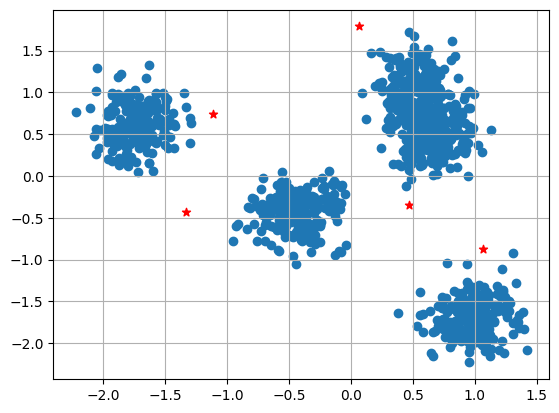

In [16]:
plt.scatter(X[:,0],X[:,1])
plt.grid(True)
for i in clusters:
    center = clusters[i]['center']
    plt.scatter(center[0],center[1],marker = '*',c = 'red')
plt.show()

Paso 6: Definición de la distancia euclidiana

Para asignar puntos de datos al centroide más cercano, definimos una función de distancia:

np.sqrt(): Calcula la raíz cuadrada de un número o array elemento por elemento.

np.sum(): Suma todos los elementos de un array o a lo largo de un eje especificado

In [17]:
def distance(p1,p2):
    return np.sqrt(np.sum((p1-p2)**2))

Paso 7: Creación de funciones de asignación y actualización

A continuación, definimos funciones para asignar puntos al centroide más cercano y actualizar los centroides basándonos en el promedio de los puntos asignados a cada clúster.

dist.append(dis): Añade la distancia calculada al dist. de la lista

curr_cluster = np.argmin(dist): Encuentra el índice del clúster más cercano seleccionando la distancia mínima.

new_center = puntos.media(eje=0): Calcula el nuevo centroide tomando la media de los puntos del grupo.

In [18]:
def assign_clusters(X, clusters):
    for idx in range(X.shape[0]):
        dist = []

        curr_x = X[idx]

        for i in range(k):
            dis = distance(curr_x,clusters[i]['center'])
            dist.append(dis)
        curr_cluster = np.argmin(dist)
        clusters[curr_cluster]['points'].append(curr_x)
    return clusters

def update_clusters(X, clusters):
    for i in range(k):
        points = np.array(clusters[i]['points'])
        if points.shape[0] > 0:
            new_center = points.mean(axis =0)
            clusters[i]['center'] = new_center

            clusters[i]['points'] = []
    return clusters

Paso 8: Predicción del clúster para los puntos de datos

Creamos una función para predecir el clúster de cada punto de datos basándonos en los centroides finales.

pred.append(np.argmin(dist)): Añade el índice del grupo más cercano (el que tiene la distancia mínima) a pred.

In [19]:
def pred_cluster(X, clusters):
    pred = []
    for i in range(X.shape[0]):
        dist = []
        for j in range(k):
            dist.append(distance(X[i],clusters[j]['center']))
        pred.append(np.argmin(dist))
    return pred

Paso 9: Asignación, actualización y predicción de los centros del clúster

Los pasos de asignación y actualización se repiten varias veces hasta que los centros del clúster se estabilizan o se alcanza un número máximo de iteraciones.

assign_clusters(X, agrupaciones): Asigna puntos de datos a los centroides más cercanos.

update_clusters(X, agrupaciones): Recalcula los centroides.

pred_cluster(X, clústeres): Predice los clústeres finales para todos los puntos de datos.

In [20]:
clusters = assign_clusters(X,clusters)
clusters = update_clusters(X,clusters)
pred = pred_cluster(X,clusters)

Paso 10: Trazando puntos de datos con centros de clúster predichos

Finalmente, representamos los puntos de datos, coloreados por sus grupos predichos, junto con los centroides actualizados.

centro = agrupaciones[i]['centro']: Recupera el centro (centroide) del cúmulo actual.

plt.scatter(center[0], center[1], marker='^', c='red'): Representa el centro del grupo como un triángulo rojo (^ marker).

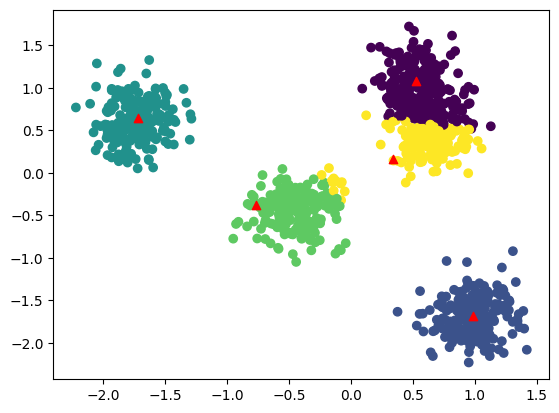

In [21]:
plt.scatter(X[:,0],X[:,1],c = pred)
for i in clusters:
    center = clusters[i]['center']
    plt.scatter(center[0],center[1],marker = '^',c = 'red')
plt.show()